# Income and Life Expectancy Across Countries in 2025

## Objective

This analysis investigates the relationship between national income per person and life expectancy across countries in 2025.

The analysis also considers:

- Population, represented by the size of each point
- Geographic region, represented by color
- Whether income has a linear or logarithmic relationship with life expectancy

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from matplotlib.ticker import FuncFormatter

## 1. Data Collection

Three datasets are used in this analysis:

- **Income:** GDP per capita for each country
- **Life expectancy:** Average expected lifespan at birth
- **Population:** Total population of each country

A separate country metadata file is later used to assign countries to geographic regions.

> All variables are filtered to the year 2025 so that the datasets can be compared consistently.

**Data source:** Gapminder

In [2]:
income = pd.read_csv("Downloads/gdp_pcap.csv")
population = pd.read_csv("Downloads/pop.csv")
life_expectancy = pd.read_csv("Downloads/lex.csv")

In [3]:
income.head()

,geo,name,1800,1801,1802,1803,1804,1805,1806,1807,...,2091,2092,2093,2094,2095,2096,2097,2098,2099,2100
0,afg,Afghanistan,560.88817,560.88817,560.88817,560.88817,560.88817,560.88817,560.88817,560.88817,...,9397.79550,9628.20479,9864.18612,10105.83025,10353.22669,10606.46351,10865.62717,11130.80231,11402.07162,11679.51560
1,ago,Angola,435.23259,436.64111,438.75389,440.86667,442.27519,444.38797,446.50074,448.61352,...,30471.68022,30991.50308,31513.98698,32038.95027,32566.20896,33095.57701,33626.86659,34159.88835,34694.45172,35230.36514
2,alb,Albania,547.53369,549.10393,550.67868,552.25795,553.84175,555.43009,557.02298,558.62044,...,57444.50359,57884.32605,58319.28840,58749.34444,59174.45223,59594.57402,60009.67615,60419.72899,60824.70684,61224.58783
3,and,Andorra,1598.53128,1601.20217,1603.87307,1607.87941,1610.55031,1613.22120,1615.89210,1618.56300,...,82535.68235,82627.86812,82718.08635,82806.37556,82892.77367,82977.31800,83060.04528,83140.99165,83220.19266,83297.68327
4,are,UAE,1332.77712,1336.78346,1342.12526,1347.46705,1352.80884,1356.81518,1362.15698,1367.49877,...,81900.09821,81885.61721,81871.47395,81857.66048,81844.16902,81830.99199,81818.12198,81805.55176,81793.27428,81781.28265


## 2. Preparing the 2025 Data

Only the country identifier, country name, and 2025 value are required from each dataset.

The value columns are renamed to descriptive names:

- `income_2025`
- `Life_Expectancy_2025`
- `population_2025`

Clear column names make the later merging and visualization steps easier to understand.

In [4]:
income_2025 = income[["geo", "name", "2025"]]

In [5]:
income_2025 = income_2025.rename(columns={"2025":"income_2025"})

In [6]:
income_2025.head()

,geo,name,income_2025
0,afg,Afghanistan,2092.54588
1,ago,Angola,7457.17479
2,alb,Albania,20361.79277
3,and,Andorra,67385.01529
4,are,UAE,72660.14487


In [7]:
life_expectancy.head()

,geo,name,1800,1801,1802,1803,1804,1805,1806,1807,...,2091,2092,2093,2094,2095,2096,2097,2098,2099,2100
0,afg,Afghanistan,28.21,28.20,28.19,28.18,28.17,28.16,28.15,28.14,...,75.92,76.07,76.21,76.36,76.50,76.65,76.80,76.95,77.10,77.25
1,ago,Angola,26.98,26.98,26.98,26.98,26.98,26.98,26.98,26.98,...,75.75,75.87,75.99,76.12,76.26,76.39,76.52,76.65,76.79,76.91
2,alb,Albania,35.40,35.40,35.40,35.40,35.40,35.40,35.40,35.40,...,88.93,89.05,89.17,89.28,89.40,89.51,89.62,89.73,89.84,89.95
3,and,Andorra,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,91.02,91.14,91.25,91.36,91.47,91.59,91.71,91.82,91.93,92.04
4,are,UAE,30.70,30.70,30.70,30.70,30.70,30.70,30.70,30.70,...,83.67,83.78,83.90,84.02,84.14,84.24,84.35,84.47,84.58,84.69


In [8]:
lex_2025 = life_expectancy[["geo", "name", "2025"]]

In [9]:
lex_2025 = lex_2025.rename(columns={"2025": "Life_Expectancy_2025"})
lex_2025.head()

,geo,name,Life_Expectancy_2025
0,afg,Afghanistan,65.11
1,ago,Angola,66.30
2,alb,Albania,79.67
3,and,Andorra,83.19
4,are,UAE,74.94


In [10]:
pop_2025 = population[["geo", "name", "2025"]]

In [11]:
pop_2025 = pop_2025.rename(columns={"2025": "population_2025"})
pop_2025.head()

,geo,name,population_2025
0,afg,Afghanistan,43844111.0
1,ago,Angola,39040039.0
2,alb,Albania,2771508.0
3,and,Andorra,82904.0
4,are,UAE,11346000.0


## 3. Combining the Datasets

The income, life expectancy, and population datasets are merged using `geo`, the common country identifier.

Using a country code rather than the country name reduces the risk of mismatches caused by spelling or naming differences.

In [12]:
df_2025 = income_2025.merge(lex_2025[["geo", "Life_Expectancy_2025"]], on=["geo"])

In [13]:
df_2025.head()

,geo,name,income_2025,Life_Expectancy_2025
0,afg,Afghanistan,2092.54588,65.11
1,ago,Angola,7457.17479,66.30
2,alb,Albania,20361.79277,79.67
3,and,Andorra,67385.01529,83.19
4,are,UAE,72660.14487,74.94


In [14]:
df_2025 = df_2025.merge(pop_2025[["geo", "population_2025"]], on ="geo")
df_2025.head()

,geo,name,income_2025,Life_Expectancy_2025,population_2025
0,afg,Afghanistan,2092.54588,65.11,43844111.0
1,ago,Angola,7457.17479,66.30,39040039.0
2,alb,Albania,20361.79277,79.67,2771508.0
3,and,Andorra,67385.01529,83.19,82904.0
4,are,UAE,72660.14487,74.94,11346000.0


In [15]:
df_2025.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   geo                   193 non-null    object 
 1   name                  193 non-null    object 
 2   income_2025           193 non-null    float64
 3   Life_Expectancy_2025  193 non-null    float64
 4   population_2025       193 non-null    float64
dtypes: float64(3), object(2)
memory usage: 7.7+ KB


### Data Quality Check

The combined dataset contains **193 countries** and five variables. The output shows that all five columns contain 193 non-null values, so there are no missing values in the variables used for the initial visualization.

The three quantitative variables—income, life expectancy, and population—are stored as numeric values.

## 4. Initial Relationship Between Income and Life Expectancy

The following scatter plot compares GDP per capita with life expectancy.

- Each point represents a country.
- The horizontal axis represents GDP per capita.
- The vertical axis represents life expectancy.
- Point size represents population.

GDP per capita is displayed on a logarithmic scale because income differs greatly between countries. The log scale prevents a small number of very high-income countries from compressing most observations into one part of the chart.

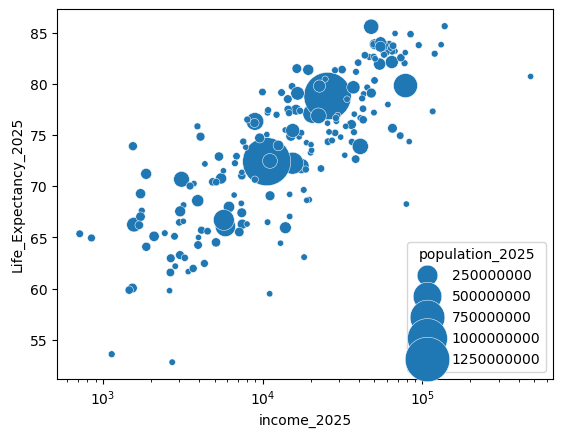

In [16]:
sns.scatterplot(data=df_2025,
               x="income_2025",
               y="Life_Expectancy_2025",
               size="population_2025",
               sizes=(20, 1200));
plt.xscale("log");

### Examining an Extreme Value

The country with the highest GDP per capita is inspected because extreme income values can strongly affect the appearance of the chart and the Pearson correlation.

This observation should not automatically be removed; it should first be understood in context.

In [17]:
df_2025.loc[df_2025["income_2025"].idxmax()]

geo                             mco
name                         Monaco
income_2025             475911.3352
Life_Expectancy_2025          80.72
population_2025             38341.0
Name: 106, dtype: object

The highest-income observation is **Monaco**, with a GDP per capita of approximately **$475,911**, a life expectancy of **80.72 years**, and a relatively small population.

Monaco's unusually high income helps explain why a logarithmic income scale is appropriate for this analysis.

## 5. Adding Geographic Regions

Country-level regional information is added to the combined dataset. This allows the visualization to show whether countries from the same broad geographic region form similar patterns.

The regional file is joined using the country code.

In [18]:
regions = pd.read_csv("Downloads/ddf--entities--geo--country.csv")
regions.head()

,country,g77_and_oecd_countries,income_3groups,income_groups,is--country,iso3166_1_alpha2,iso3166_1_alpha3,iso3166_1_numeric,iso3166_2,landlocked,...,name,un_sdg_ldc,un_sdg_region,un_state,unhcr_region,unicef_region,unicode_region_subtag,west_and_rest,world_4region,world_6region
0,abkh,others,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,...,Abkhazia,NaN,NaN,False,NaN,NaN,NaN,NaN,europe,europe_central_asia
1,abw,others,high_income,high_income,True,AW,ABW,533.0,NaN,coastline,...,Aruba,un_not_least_developed,un_latin_america_and_the_caribbean,False,unhcr_americas,NaN,AW,NaN,americas,america
2,afg,g77,low_income,low_income,True,AF,AFG,4.0,NaN,landlocked,...,Afghanistan,un_least_developed,un_central_and_southern_asia,True,unhcr_asia_pacific,sa,AF,rest,asia,south_asia
3,ago,g77,middle_income,lower_middle_income,True,AO,AGO,24.0,NaN,coastline,...,Angola,un_least_developed,un_sub_saharan_africa,True,unhcr_southern_africa,ssa,AO,rest,africa,sub_saharan_africa
4,aia,others,NaN,NaN,True,AI,AIA,660.0,NaN,coastline,...,Anguilla,un_not_least_developed,un_latin_america_and_the_caribbean,False,unhcr_americas,NaN,AI,NaN,americas,america


In [19]:
regions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 273 entries, 0 to 272
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   country                 273 non-null    object 
 1   g77_and_oecd_countries  259 non-null    object 
 2   income_3groups          218 non-null    object 
 3   income_groups           218 non-null    object 
 4   is--country             273 non-null    bool   
 5   iso3166_1_alpha2        248 non-null    object 
 6   iso3166_1_alpha3        247 non-null    object 
 7   iso3166_1_numeric       247 non-null    float64
 8   iso3166_2               1 non-null      object 
 9   landlocked              255 non-null    object 
 10  latitude                241 non-null    float64
 11  longitude               241 non-null    float64
 12  main_religion_2008      216 non-null    object 
 13  name                    273 non-null    object 
 14  un_sdg_ldc              249 non-null    ob

In [20]:
df_2025 = df_2025.merge(regions[["country","world_4region"]],
             left_on="geo",
             right_on="country")

In [21]:
df_2025.head()

,geo,name,income_2025,Life_Expectancy_2025,population_2025,country,world_4region
0,afg,Afghanistan,2092.54588,65.11,43844111.0,afg,asia
1,ago,Angola,7457.17479,66.30,39040039.0,ago,africa
2,alb,Albania,20361.79277,79.67,2771508.0,alb,europe
3,and,Andorra,67385.01529,83.19,82904.0,and,europe
4,are,UAE,72660.14487,74.94,11346000.0,are,asia


In [22]:
df_2025 = df_2025.drop(columns="country")

In [23]:
df_2025.head()

,geo,name,income_2025,Life_Expectancy_2025,population_2025,world_4region
0,afg,Afghanistan,2092.54588,65.11,43844111.0,asia
1,ago,Angola,7457.17479,66.30,39040039.0,africa
2,alb,Albania,20361.79277,79.67,2771508.0,europe
3,and,Andorra,67385.01529,83.19,82904.0,europe
4,are,UAE,72660.14487,74.94,11346000.0,asia


## 6. Regional Bubble Chart

The final chart includes three dimensions in addition to country:

- **Position on the x-axis:** GDP per capita
- **Position on the y-axis:** Life expectancy
- **Bubble size:** Population
- **Bubble color:** Geographic region

This design makes it possible to compare both the overall income–health relationship and regional differences.

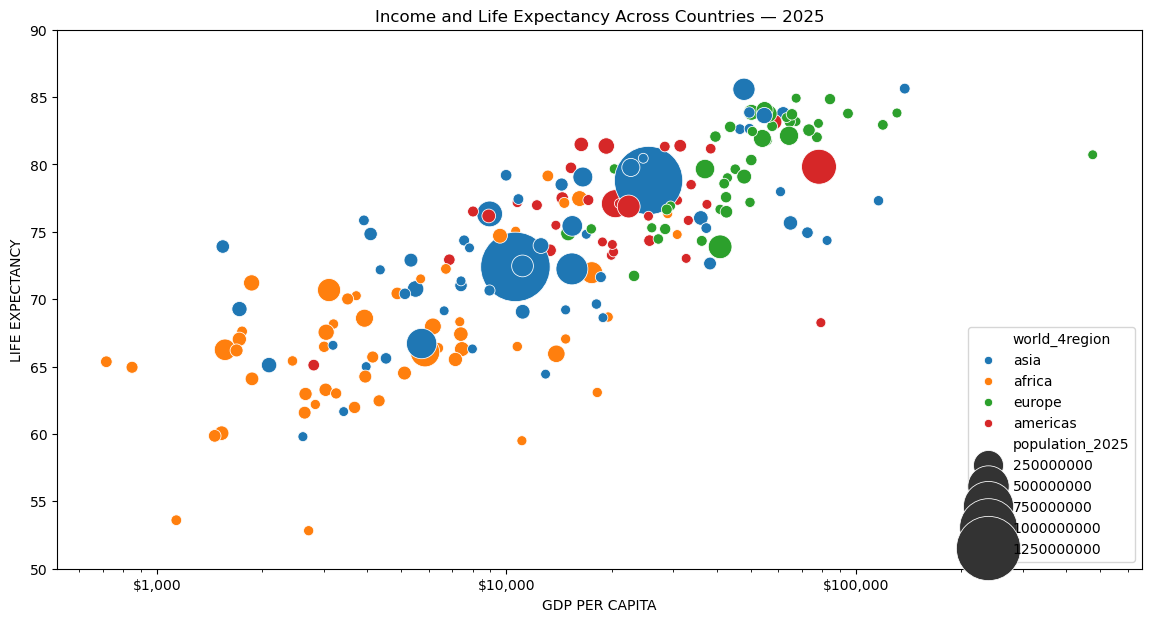

In [24]:
plt.figure(figsize=(14, 7))
sns.scatterplot(data=df_2025,
               x="income_2025",
               y="Life_Expectancy_2025",
               size="population_2025",
               sizes=(50, 2500),
               hue="world_4region",
               legend="brief");
plt.xscale("log");
plt.ylim(50, 90)
plt.xlabel("GDP PER CAPITA")
plt.ylabel("LIFE EXPECTANCY");
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
);
plt.title("Income and Life Expectancy Across Countries — 2025");

### Interpretation

The chart shows a positive relationship between income and life expectancy: countries with higher GDP per capita generally have higher life expectancy.

However, the pattern is nonlinear. Life expectancy increases more sharply among lower- and middle-income countries, while the increase becomes smaller among high-income countries. This suggests diminishing improvements in life expectancy as income rises.

Regional clustering is also visible, indicating that countries with similar geographic and socioeconomic conditions often occupy similar parts of the chart. Population size varies considerably, but the largest countries do not necessarily have the highest income or life expectancy.

These patterns represent associations and should not be interpreted as proof that income alone causes higher life expectancy.

## 7. Correlation Analysis

Pearson correlation is calculated twice:

1. Between GDP per capita and life expectancy
2. Between the logarithm of GDP per capita and life expectancy

Comparing these values helps determine whether the relationship is better represented using raw income or logarithmic income.

In [25]:
df_2025["income_2025"].corr(df_2025["Life_Expectancy_2025"])

0.4889493928116172

In [26]:
np.log10(df_2025["income_2025"]).corr(df_2025["Life_Expectancy_2025"])

0.7997019565436808

## 8. Key Findings

The correlation between raw GDP per capita and life expectancy is approximately **0.489**, indicating a moderate positive linear relationship.

After applying a base-10 logarithmic transformation to GDP per capita, the correlation increases to approximately **0.800**. This is a strong positive relationship and indicates that log income describes the observed pattern more effectively than raw income.

### Conclusion

Countries with higher income per person generally have longer life expectancy, but the relationship is not purely linear. Income differences appear to matter more at lower income levels, while gains in life expectancy become smaller at higher income levels.

Income is only one possible influence on life expectancy. Other factors—such as healthcare access, education, public health, inequality, governance, conflict, and environmental conditions—may also contribute to the differences between countries.

### Limitations

- The analysis uses data from only one year and therefore cannot establish trends over time.
- Correlation does not establish causation.
- Country-level averages can hide inequalities within countries.
- The results may depend on how GDP per capita and life expectancy were estimated.
- The 2025 figures may include projections rather than fully observed values, depending on the source datasets.